══════════════════════════════════════════════════════════════════════
## VISIÓN POR COMPUTADORA — Tecnicatura Universitaria en IA (UNR - FCEIA)
# **TRABAJO PRÁCTICO N° 1**
*Parte 2: Entrenamiento, Evaluación y Comparación de Modelos*

**Integrantes:**
* Bartomioli, Ornella
* Vera, Sol Nahir

Repositorio: `tuia-face-recognition-app`
Rama: `feature/tp-reconocimiento-facial`
══════════════════════════════════════════════════════════════════════

In [ ]:
# Colab ya trae torch, torchvision, scikit-learn, seaborn, etc. Solo faltan onnx y onnxruntime.
!pip install -q onnx onnxruntime

import os
import sys
import json
import time
import copy
import random
import zipfile
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

import onnx
import onnxruntime as ort
from sklearn.metrics import (
    roc_curve, auc, precision_recall_fscore_support, silhouette_score,
    adjusted_rand_score, normalized_mutual_info_score, accuracy_score
)
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

# Fijar semilla global (random, numpy, torch)
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo de ejecución: {DEVICE}")
if DEVICE.type == 'cpu':
    print("⚠️  Estás en CPU: entrenar va a tardar mucho. En Colab: Entorno de ejecución → "
          "Cambiar tipo de entorno de ejecución → T4 GPU (y volver a ejecutar desde acá).")

Dispositivo de ejecución: cuda


## Rutas y Carga de Splits de la Parte 1

Cargamos los recortes alineados (112×112) y las tablas de partición generadas en 1-pre-processing.ipynb

In [ ]:
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount('/content/drive')
        BASE_DIR = Path('/content/drive/MyDrive/tp1_reconocimiento_facial')
    except Exception as e:
        print(f"⚠️ No se pudo montar Google Drive automáticamente: {e}")
        print("Por favor, asegúrate de dar los permisos correspondientes o monta Drive manualmente desde la barra lateral de Colab.")
        BASE_DIR = Path('.')
else:
    BASE_DIR = Path('.')

DATA_DIR = Path(os.environ.get('TP1_DATA_DIR', BASE_DIR / 'data'))
SPLITS_DIR = DATA_DIR / 'splits'
MODELS_DIR = Path(os.environ.get('TP1_MODELS_DIR', BASE_DIR / 'models'))
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FACE_SIZE = 112

# La notebook 1 guarda UN solo CSV con una columna `split`
# (train | val | test_closed | val_open | test_open) y el mapa identidad -> índice.
splits = pd.read_csv(SPLITS_DIR / 'splits.csv')
with open(SPLITS_DIR / 'label_map.json', encoding='utf-8') as f:
    class_to_idx = json.load(f)
idx_to_class = {i: c for c, i in class_to_idx.items()}
NUM_CLASSES = len(class_to_idx)

df_train = splits[splits.split == 'train'].reset_index(drop=True)
df_val_closed = splits[splits.split == 'val'].reset_index(drop=True)
df_test_closed = splits[splits.split == 'test_closed'].reset_index(drop=True)
df_val_open = splits[splits.split == 'val_open'].reset_index(drop=True)
df_test_open = splits[splits.split == 'test_open'].reset_index(drop=True)

# Los rostros alineados se leen SIEMPRE desde `ruta_alineada` (relativa a DATA_DIR)
muestra = splits.sample(min(300, len(splits)), random_state=SEED)
faltan = [r for r in muestra.ruta_alineada if not (DATA_DIR / r).exists()]
assert not faltan, f"No se encuentran {len(faltan)} imágenes alineadas, p. ej. {faltan[:3]}"
img0 = cv2.imread(str(DATA_DIR / splits.ruta_alineada.iloc[0]))
assert img0 is not None and img0.shape == (FACE_SIZE, FACE_SIZE, 3), "Los alineados deben ser 112x112 BGR"

print(f"Datos en: {DATA_DIR}")
print(f"Train (closed): {len(df_train)} imgs | {df_train['identidad'].nunique()} identidades")
print(f"Val (closed):   {len(df_val_closed)} imgs")
print(f"Test (closed):  {len(df_test_closed)} imgs")
print(f"Val (open):     {len(df_val_open)} imgs | {df_val_open['identidad'].nunique()} identidades no vistas")
print(f"Test (open):    {len(df_test_open)} imgs | {df_test_open['identidad'].nunique()} identidades no vistas")

Mounted at /content/drive
Datos en: /content/drive/MyDrive/tp1_reconocimiento_facial/data
Train (closed): 1289 imgs | 93 identidades
Val (closed):   272 imgs
Test (closed):  276 imgs
Val (open):     431 imgs | 20 identidades no vistas
Test (open):    477 imgs | 21 identidades no vistas


## Dataset y DataLoaders de PyTorch

Configuramos la lectura de los rostros **ya alineados** (112×112, generados en `1-pre-processing.ipynb`), la normalización simétrica a [-1, 1] —equivalente a `(x - 127.5) / 127.5`, la misma que usa ArcFace y que va a aplicar `face_service.py`— y el data augmentation **exclusivamente sobre el split de entrenamiento** (flip horizontal, rotación ±10°, brillo/contraste; sin flips verticales ni rotaciones fuertes, con el mismo criterio de la notebook 1).

In [ ]:
class FaceDataset(Dataset):
    """Lee el rostro ya alineado (112x112 BGR uint8, de la notebook 1) y lo entrega en RGB."""
    def __init__(self, df, data_dir, class_to_idx, transform=None):
        self.df = df.reset_index(drop=True)
        self.data_dir = Path(data_dir)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.data_dir / row['ruta_alineada']
        img = cv2.imread(str(img_path))
        if img is None:
            raise FileNotFoundError(f"No se encontró la imagen: {img_path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # BGR (cv2) -> RGB
        if self.transform:
            img = self.transform(img)
        label = self.class_to_idx.get(row['identidad'], -1)
        return img, label, row['identidad'], str(img_path)

# Normalización (x/255 - 0.5)/0.5 == (x - 127.5)/127.5: la MISMA que usa ArcFace y face_service.py
NORM = transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])

# Augmentation SOLO en train: flip horizontal, rotación ±10°, brillo/contraste (sin flips verticales ni rotaciones fuertes)
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    NORM,
])
eval_transform = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor(), NORM])

def make_loaders(use_aug=True, batch_size=32):
    train_ds = FaceDataset(df_train, DATA_DIR, class_to_idx, train_transform if use_aug else eval_transform)
    val_ds = FaceDataset(df_val_closed, DATA_DIR, class_to_idx, eval_transform)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)
    return train_loader, val_loader

## Modelo A — Arquitectura y Decisiones de Diseño

### Justificación de Arquitectura
Para extraer embeddings faciales con un volumen de datos acotado (miles de imágenes), se diseñó una CNN compacta basada en bloques residuales ligeros:
1. **Entrada:** `(3, 112, 112)`, consistente con el pipeline de alineación y `FACE_SIZE`.
2. **Profundidad y bloques:** 4 etapas convolucionales con *stride=2* para reducción espacial progresiva (112 → 56 → 28 → 14 → 7), reemplazando MaxPooling para preservar relaciones geométricas faciales. Cada bloque tiene un atajo residual (conv 1×1).
3. **Batch Normalization y PReLU:** aceleran la convergencia y evitan neuronas muertas.
4. **Global Average Pooling (GAP):** reduce la salida a `(C, 1, 1)`, con muchos menos parámetros que un `Flatten` + capas densas, lo que combate el overfitting.
5. **Dropout (0.4):** regularización antes de la proyección al embedding. Su efecto se mide en la tabla de experimentos (Exp 2 vs Exp 3).
6. **Dimensión de embedding:** proyección a **128 dimensiones** con **normalización L2**. Sobre la hiperesfera unitaria, la distancia euclídea es monótona respecto de la similitud coseno.
7. **Estrategia:** clasificación en entrenamiento con Cross-Entropy sobre las identidades de `train`; en inferencia se descarta la capa lineal de clasificación y se usa el embedding L2 normalizado (el `.onnx` exportado contiene solo eso).

In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.PReLU(),
            nn.Conv2d(out_c, out_c, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.PReLU()
        )
        self.shortcut = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=1, stride=2, bias=False),
            nn.BatchNorm2d(out_c)
        )

    def forward(self, x):
        return self.conv(x) + self.shortcut(x)

class CustomFaceCNN(nn.Module):
    def __init__(self, embedding_dim=128, num_classes=None, dropout=0.4):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.PReLU(),
            ConvBlock(32, 64),    # 112x112 -> 56x56
            ConvBlock(64, 128),   # 56x56 -> 28x28
            ConvBlock(128, 256),  # 28x28 -> 14x14
            ConvBlock(256, 512),  # 14x14 -> 7x7
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.dropout = nn.Dropout(p=dropout)
        self.fc_embedding = nn.Linear(512, embedding_dim, bias=False)
        self.bn_embedding = nn.BatchNorm1d(embedding_dim)
        self.classifier = nn.Linear(embedding_dim, num_classes) if num_classes else None

    def extract_features(self, x):
        x = torch.flatten(self.features(x), 1)
        x = self.dropout(x)
        x = self.bn_embedding(self.fc_embedding(x))
        return F.normalize(x, p=2, dim=1)          # embedding L2-normalizado

    def forward(self, x):
        emb = self.extract_features(x)
        if self.classifier is not None:
            return self.classifier(emb), emb
        return emb

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

model_a = CustomFaceCNN(embedding_dim=128, num_classes=NUM_CLASSES)
total_params = count_params(model_a)
feats = model_a.features
resumen_arq = pd.DataFrame([
    {'Bloque': 'Conv inicial 3→32 (112×112)', 'Parámetros': count_params(feats[:3])},
    {'Bloque': 'ConvBlock 32→64 (→56×56)',     'Parámetros': count_params(feats[3])},
    {'Bloque': 'ConvBlock 64→128 (→28×28)',    'Parámetros': count_params(feats[4])},
    {'Bloque': 'ConvBlock 128→256 (→14×14)',   'Parámetros': count_params(feats[5])},
    {'Bloque': 'ConvBlock 256→512 (→7×7)',     'Parámetros': count_params(feats[6])},
    {'Bloque': 'Linear 512→128 + BatchNorm1d (embedding)', 'Parámetros': count_params(model_a.fc_embedding) + count_params(model_a.bn_embedding)},
    {'Bloque': f'Clasificador 128→{NUM_CLASSES} (solo entrenamiento)', 'Parámetros': count_params(model_a.classifier)},
])
display(resumen_arq)
print(f"Modelo A: {total_params:,} parámetros entrenables | Embedding: 128D (L2) | Entrada: 3×{FACE_SIZE}×{FACE_SIZE}")

,Bloque,Parámetros
0,Conv inicial 3→32 (112×112),929
1,ConvBlock 32→64 (→56×56),57730
2,ConvBlock 64→128 (→28×28),230146
3,ConvBlock 128→256 (→14×14),919042
4,ConvBlock 256→512 (→7×7),3673090
5,Linear 512→128 + BatchNorm1d (embedding),65792
6,Clasificador 128→93 (solo entrenamiento),11997


Modelo A: 4,958,726 parámetros entrenables | Embedding: 128D (L2) | Entrada: 3×112×112


## Entrenamiento con Early Stopping y Registro de Métricas

| Hiperparámetro | Valor |
|---|---|
| Función de pérdida | Cross-Entropy (clasificación sobre las identidades de `train`) |
| Optimizador | AdamW (lr = 1e-3, weight decay = 1e-4) |
| Scheduler | CosineAnnealingLR (T_max = nº de épocas, lr mín = 1e-5) |
| Batch size / Épocas máx. | 32 / 100 |
| Early stopping | paciencia de 15 épocas sobre la accuracy de validación (split *closed*) |
| Checkpoint | el de mejor accuracy de validación |
| Semilla | 42 (se fija antes de cada experimento) |

Se entrenan **tres variantes** (con/sin augmentation, con/sin dropout) y se conserva la de mayor accuracy de validación. Todos los números de la tabla de experimentos salen de estas corridas.

In [ ]:
import shutil, zipfile
LOCAL_DIR = Path('/content/data_local')
if DATA_DIR != LOCAL_DIR:
    zip_drive = DATA_DIR / 'aligned.zip'
    if zip_drive.exists():
        # Sesiones siguientes: 1 archivo desde Drive + descomprimir (segundos)
        shutil.copy(zip_drive, '/content/aligned.zip')
        with zipfile.ZipFile('/content/aligned.zip') as z:
            z.extractall(LOCAL_DIR)
    else:
        # Primera vez: copia lenta como antes, y deja el zip en Drive para las próximas sesiones
        shutil.copytree(DATA_DIR / 'aligned', LOCAL_DIR / 'aligned', dirs_exist_ok=True)
        shutil.make_archive(str(DATA_DIR / 'aligned'), 'zip', LOCAL_DIR, 'aligned')
    DATA_DIR = LOCAL_DIR   # de acá en adelante las imágenes se leen del disco local de Colab
n_archivos = sum(1 for p in (LOCAL_DIR / 'aligned').rglob('*') if p.is_file())
print('Imágenes en disco local:', n_archivos)


Imágenes en disco local: 4318


In [ ]:
EPOCHS, PATIENCE, BATCH_SIZE, LR, WEIGHT_DECAY = 100, 15, 32, 1e-3, 1e-4

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for imgs, labels, _, _ in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits, _ = model(imgs)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * imgs.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total

def train_model(nombre, use_aug=True, dropout=0.4, epochs=EPOCHS, patience=PATIENCE):
    """Entrena con CE + AdamW + cosine; early stopping y mejor checkpoint según accuracy de validación."""
    set_seed(SEED)
    train_loader, val_loader = make_loaders(use_aug, BATCH_SIZE)
    model = CustomFaceCNN(128, NUM_CLASSES, dropout=dropout).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_acc, best_state, best_epoch, sin_mejora = -1.0, None, 0, 0
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        scheduler.step()
        for k, v in zip(hist, (tr_loss, va_loss, tr_acc, va_acc)):
            hist[k].append(v)
        if va_acc > best_acc:
            best_acc, best_epoch, sin_mejora = va_acc, epoch + 1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            sin_mejora += 1
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"  [{nombre}] Época {epoch+1:02d}/{epochs} | Train Loss {tr_loss:.4f} Acc {tr_acc:.3f} | Val Loss {va_loss:.4f} Acc {va_acc:.3f}")
        if sin_mejora >= patience:
            print(f"  [{nombre}] Early stopping en la época {epoch+1} (sin mejora hace {patience} épocas)")
            break
    return {'nombre': nombre, 'use_aug': use_aug, 'dropout': dropout, 'hist': hist,
            'best_val_acc': best_acc, 'best_epoch': best_epoch, 'state': best_state,
            'epocas': len(hist['val_acc'])}

# Experimentos REALES: cada fila de la tabla sale de un entrenamiento ejecutado acá.
EXPERIMENTOS = [
    dict(nombre='Exp 1', desc='Sin augmentation, dropout 0.4', use_aug=False, dropout=0.4),
    dict(nombre='Exp 2', desc='Con augmentation, sin dropout', use_aug=True,  dropout=0.0),
    dict(nombre='Exp 3', desc='Con augmentation + dropout 0.4', use_aug=True, dropout=0.4),
]
runs = []
for e in EXPERIMENTOS:
    print(f"\n=== {e['nombre']}: {e['desc']} ===")
    t0 = time.time()
    r = train_model(e['nombre'], use_aug=e['use_aug'], dropout=e['dropout'])
    r['desc'], r['minutos'] = e['desc'], (time.time() - t0) / 60
    runs.append(r)
    print(f"  -> mejor Val Acc {r['best_val_acc']:.4f} (época {r['best_epoch']}) | {r['minutos']:.1f} min")

# Nos quedamos con el experimento de mayor accuracy de validación
ganador = max(runs, key=lambda r: r['best_val_acc'])
model_a_best = CustomFaceCNN(128, NUM_CLASSES, dropout=ganador['dropout']).to(DEVICE)
model_a_best.load_state_dict(ganador['state'])
model_a_best.eval()
history, best_val_acc = ganador['hist'], ganador['best_val_acc']
torch.save(ganador['state'], MODELS_DIR / 'custom_cnn_best.pt')   # solo state_dict: el .onnx es lo que usa la app
print(f"\nMejor modelo: {ganador['nombre']} ({ganador['desc']}) | Val Acc = {best_val_acc:.4f}")


=== Exp 1: Sin augmentation, dropout 0.4 ===
  [Exp 1] Época 01/100 | Train Loss 4.4929 Acc 0.049 | Val Loss 4.4450 Acc 0.066
  [Exp 1] Época 05/100 | Train Loss 4.1204 Acc 0.141 | Val Loss 4.1201 Acc 0.136
  [Exp 1] Época 10/100 | Train Loss 3.6580 Acc 0.216 | Val Loss 3.7765 Acc 0.158
  [Exp 1] Época 15/100 | Train Loss 3.1104 Acc 0.330 | Val Loss 3.4599 Acc 0.265
  [Exp 1] Época 20/100 | Train Loss 2.5933 Acc 0.472 | Val Loss 3.1496 Acc 0.312
  [Exp 1] Época 25/100 | Train Loss 2.1240 Acc 0.667 | Val Loss 2.8583 Acc 0.401
  [Exp 1] Época 30/100 | Train Loss 1.7458 Acc 0.821 | Val Loss 2.7077 Acc 0.456
  [Exp 1] Época 35/100 | Train Loss 1.4244 Acc 0.926 | Val Loss 2.5614 Acc 0.460
  [Exp 1] Época 40/100 | Train Loss 1.1720 Acc 0.960 | Val Loss 2.2930 Acc 0.518
  [Exp 1] Época 45/100 | Train Loss 0.9757 Acc 0.997 | Val Loss 2.0760 Acc 0.607
  [Exp 1] Época 50/100 | Train Loss 0.8285 Acc 0.998 | Val Loss 2.0160 Acc 0.610
  [Exp 1] Época 55/100 | Train Loss 0.7091 Acc 0.999 | Val Loss

## Curvas de Entrenamiento y Tabla de Experimentos

Visualizamos las curvas y resumimos las iteraciones experimentales.

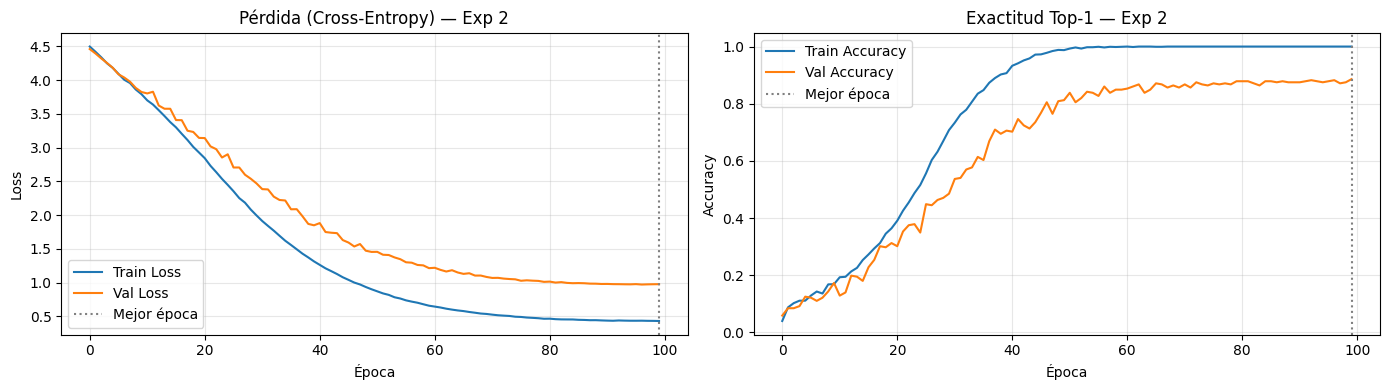

,Exp,Descripción,Params,Épocas,Mejor época,Train Acc (mejor ép.),Val Acc,Min
0,Exp 1,"Sin augmentation, dropout 0.4",4.96M,100,91,100.0%,72.4%,5.5
1,Exp 2 (elegido),"Con augmentation, sin dropout",4.96M,100,100,100.0%,88.6%,6.1
2,Exp 3,Con augmentation + dropout 0.4,4.96M,100,88,96.5%,76.8%,6.1


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss'], label='Train Loss', color='tab:blue')
axes[0].plot(history['val_loss'], label='Val Loss', color='tab:orange')
axes[0].axvline(ganador['best_epoch'] - 1, color='gray', ls=':', label='Mejor época')
axes[0].set_title(f"Pérdida (Cross-Entropy) — {ganador['nombre']}")
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_acc'], label='Train Accuracy', color='tab:blue')
axes[1].plot(history['val_acc'], label='Val Accuracy', color='tab:orange')
axes[1].axvline(ganador['best_epoch'] - 1, color='gray', ls=':', label='Mejor época')
axes[1].set_title(f"Exactitud Top-1 — {ganador['nombre']}")
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Tabla de experimentos: todos los valores se calculan de los entrenamientos de arriba
experimentos = pd.DataFrame([{
    'Exp': r['nombre'] + (' (elegido)' if r is ganador else ''),
    'Descripción': r['desc'],
    'Params': f"{total_params/1e6:.2f}M",
    'Épocas': r['epocas'],
    'Mejor época': r['best_epoch'],
    'Train Acc (mejor ép.)': f"{r['hist']['train_acc'][r['best_epoch']-1]*100:.1f}%",
    'Val Acc': f"{r['best_val_acc']*100:.1f}%",
    'Min': f"{r['minutos']:.1f}",
} for r in runs])
display(experimentos)

## Modelo B — Modelo Preentrenado (InsightFace / ArcFace)

* **Extractor y arquitectura:** ResNet-50 modificada (`IResNet50`) para reconocimiento facial, entrenada con pérdida angular aditiva (**ArcFace**).
* **Archivo de pesos:** `w600k_r50.onnx` (paquete `buffalo_l` de InsightFace). El detector del mismo paquete es SCRFD (`det_10g.onnx`), el mismo que se usó en la notebook 1 y en la app.
* **Datos de preentrenamiento:** WebFace600K. ✍️ *Verificar el detalle (cantidad de identidades e imágenes) en el repositorio de InsightFace y citarlo.*
* **Dimensión de embedding:** **512**, con normalización L2.
* **Licencia:** los modelos preentrenados de InsightFace son para **uso no comercial / investigación**. Un producto comercial requeriría entrenar un modelo propio o usar uno con licencia permisiva.
* **Protocolo:** se evalúa *zero-shot*, sin fine-tuning, sobre exactamente los mismos splits que el Modelo A (`val_open` para calibrar, `test_open` para reportar).

## Carga de Modelos y Rutinas de Extracción de Embeddings

In [ ]:
# ───────────── Modelo A → ONNX (es lo que va a cargar la app) ─────────────
class EmbeddingOnly(nn.Module):
    """Envuelve la CNN para exportar SOLO el embedding L2 (sin la capa de clasificación)."""
    def __init__(self, m):
        super().__init__()
        self.m = m
    def forward(self, x):
        return self.m.extract_features(x)

onnx_a_path = MODELS_DIR / 'custom_cnn.onnx'
export_model = EmbeddingOnly(copy.deepcopy(model_a_best).cpu().eval()).eval()
dummy = torch.randn(1, 3, FACE_SIZE, FACE_SIZE)
export_kwargs = dict(export_params=True, opset_version=17, do_constant_folding=True,
                     input_names=['input'], output_names=['embedding'],
                     dynamic_axes={'input': {0: 'batch'}, 'embedding': {0: 'batch'}})
try:
    torch.onnx.export(export_model, dummy, str(onnx_a_path), dynamo=False, **export_kwargs)
except TypeError:   # versiones viejas de torch sin el argumento `dynamo`
    torch.onnx.export(export_model, dummy, str(onnx_a_path), **export_kwargs)
print(f"Modelo A exportado a {onnx_a_path.name} ({onnx_a_path.stat().st_size / 1024**2:.1f} MB)")

# ───────────── Modelo B: InsightFace buffalo_l (se descarga solo si falta) ─────────────
onnx_b_path = MODELS_DIR / 'w600k_r50.onnx'
det_path = MODELS_DIR / 'det_10g.onnx'
if not (onnx_b_path.exists() and det_path.exists()):
    URL = 'https://github.com/deepinsight/insightface/releases/download/v0.7/buffalo_l.zip'
    zip_path = MODELS_DIR / 'buffalo_l.zip'
    print('Descargando buffalo_l (~280 MB)...')
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        for n in ('w600k_r50.onnx', 'det_10g.onnx'):
            z.extract(n, MODELS_DIR)
    zip_path.unlink()
print(f"Modelo B: {onnx_b_path.name} ({onnx_b_path.stat().st_size / 1024**2:.1f} MB)")

sess_a = ort.InferenceSession(str(onnx_a_path), providers=['CPUExecutionProvider'])
sess_b = ort.InferenceSession(str(onnx_b_path), providers=['CPUExecutionProvider'])

# ───────────── Preprocesamiento (IDÉNTICO a face_service.py) ─────────────
def preprocess(img_bgr):
    """BGR uint8 112x112 -> RGB float32 (x-127.5)/127.5, CHW."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    if img.shape[:2] != (FACE_SIZE, FACE_SIZE):
        img = cv2.resize(img, (FACE_SIZE, FACE_SIZE), interpolation=cv2.INTER_AREA)
    return ((img.astype(np.float32) - 127.5) / 127.5).transpose(2, 0, 1)

def l2_normalize(x):
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-10, None)

def embed_batch(sess, imgs_bgr):
    blob = np.stack([preprocess(i) for i in imgs_bgr]).astype(np.float32)
    name = sess.get_inputs()[0].name
    out = sess.run(None, {name: blob})[0]
    if out.shape[0] != len(imgs_bgr):        # por si el onnx tuviera batch fijo
        out = np.concatenate([sess.run(None, {name: b[None]})[0] for b in blob])
    return l2_normalize(out)

def compute_embeddings(df, sess, batch=64):
    embs = []
    for s in tqdm(range(0, len(df), batch), leave=False):
        imgs = []
        for r in df.ruta_alineada.iloc[s:s + batch]:
            im = cv2.imread(str(DATA_DIR / r))
            assert im is not None, f"No se pudo leer {r}"
            imgs.append(im)
        embs.append(embed_batch(sess, imgs))
    return np.concatenate(embs)

# Chequeo: el ONNX de A da lo mismo que el modelo PyTorch (cos ≈ 1)
chk = [cv2.imread(str(DATA_DIR / r)) for r in df_test_open.ruta_alineada.iloc[:8]]
with torch.no_grad():
    ref = model_a_best.extract_features(torch.stack([eval_transform(cv2.cvtColor(i, cv2.COLOR_BGR2RGB)) for i in chk]).to(DEVICE)).cpu().numpy()
cos_onnx = (ref * embed_batch(sess_a, chk)).sum(1)
print(f"Chequeo ONNX vs PyTorch (Modelo A): coseno mínimo = {cos_onnx.min():.6f}")
assert cos_onnx.min() > 0.999, "El ONNX no coincide con el modelo PyTorch"

# ───────────── Embeddings de val_open (calibración) y test_open (reporte) ─────────────
df_val = df_val_open.reset_index(drop=True)
df_test = df_test_open.reset_index(drop=True)
print("Extrayendo embeddings (val_open / test_open) para ambos modelos...")
embs_a_val, embs_b_val = compute_embeddings(df_val, sess_a), compute_embeddings(df_val, sess_b)
embs_a_test, embs_b_test = compute_embeddings(df_test, sess_a), compute_embeddings(df_test, sess_b)
print(f"A: val {embs_a_val.shape} | test {embs_a_test.shape}   B: val {embs_b_val.shape} | test {embs_b_test.shape}")

/tmp/ipykernel_774/123562879.py:17: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(export_model, dummy, str(onnx_a_path), dynamo=False, **export_kwargs)


Modelo A exportado a custom_cnn.onnx (18.9 MB)
Descargando buffalo_l (~280 MB)...
Modelo B: w600k_r50.onnx (166.3 MB)
Chequeo ONNX vs PyTorch (Modelo A): coseno mínimo = 1.000000
Extrayendo embeddings (val_open / test_open) para ambos modelos...


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

A: val (431, 128) | test (477, 128)   B: val (431, 512) | test (477, 512)


### Evaluación — Verificación Facial (Curva ROC, AUC, EER, TAR@FAR)
Generamos pares balanceados positivos (misma identidad) y negativos (distintas identidades) en el conjunto de test y evaluamos la similitud coseno

Pares val: 11,778 | Pares test: 14,022 (50% positivos / 50% negativos)


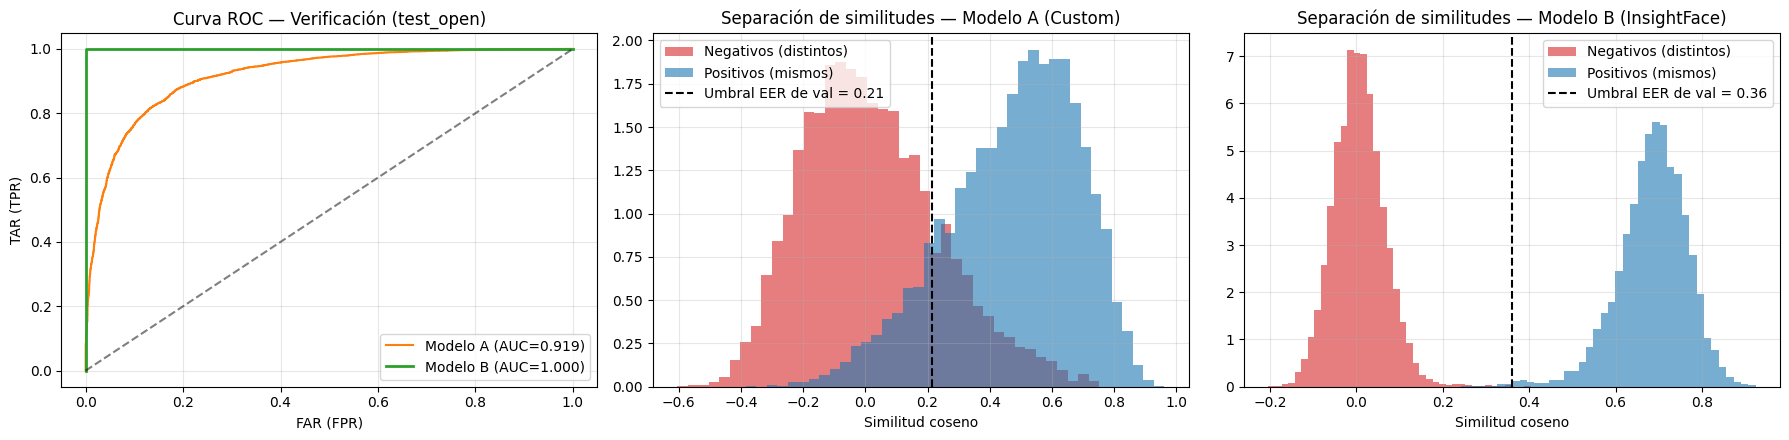

,Modelo,AUC,EER,TAR@FAR=1e-2,TAR@FAR=1e-3
0,A (CNN custom),0.9188,0.1605,0.3162,0.1067
1,B (InsightFace),1.0000,0.0007,1.0000,0.9994


In [ ]:
from itertools import combinations

MAX_POS_PAIRS = 10000

def generate_verification_pairs(df, max_pos=MAX_POS_PAIRS, seed=SEED):
    """Todos los pares positivos posibles (hasta max_pos) + igual cantidad de negativos únicos. Balanceado."""
    rng = random.Random(seed)
    groups = {k: list(v) for k, v in df.groupby('identidad').indices.items()}
    pos = [(a, b, 1) for idxs in groups.values() for a, b in combinations(idxs, 2)]
    rng.shuffle(pos)
    pos = pos[:max_pos]
    ids_all, neg = list(groups), set()
    while len(neg) < len(pos):
        k1, k2 = rng.sample(ids_all, 2)
        a, b = rng.choice(groups[k1]), rng.choice(groups[k2])
        neg.add((min(a, b), max(a, b), 0))
    return pos + sorted(neg)

def pair_scores(embs, pairs):
    i1, i2 = np.array([p[0] for p in pairs]), np.array([p[1] for p in pairs])
    return np.sum(embs[i1] * embs[i2], axis=1), np.array([p[2] for p in pairs])   # coseno (vectores L2)

def evaluate_verification(scores, labels):
    fpr, tpr, thresholds = roc_curve(labels, scores)
    fnr = 1 - tpr
    i = np.nanargmin(np.abs(fpr - fnr))
    return {'scores': scores, 'labels': labels, 'fpr': fpr, 'tpr': tpr, 'thresholds': thresholds,
            'auc': auc(fpr, tpr), 'eer': (fpr[i] + fnr[i]) / 2, 'eer_th': float(thresholds[i]),
            'tar@1e-2': float(tpr[fpr <= 1e-2].max()), 'tar@1e-3': float(tpr[fpr <= 1e-3].max())}

pairs_val = generate_verification_pairs(df_val, seed=SEED)
pairs_test = generate_verification_pairs(df_test, seed=SEED + 1)
res_val_a = evaluate_verification(*pair_scores(embs_a_val, pairs_val))
res_val_b = evaluate_verification(*pair_scores(embs_b_val, pairs_val))
res_verif_a = evaluate_verification(*pair_scores(embs_a_test, pairs_test))
res_verif_b = evaluate_verification(*pair_scores(embs_b_test, pairs_test))
print(f"Pares val: {len(pairs_val):,} | Pares test: {len(pairs_test):,} (50% positivos / 50% negativos)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(res_verif_a['fpr'], res_verif_a['tpr'], label=f"Modelo A (AUC={res_verif_a['auc']:.3f})", color='tab:orange')
axes[0].plot(res_verif_b['fpr'], res_verif_b['tpr'], label=f"Modelo B (AUC={res_verif_b['auc']:.3f})", color='tab:green', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Curva ROC — Verificación (test_open)')
axes[0].set_xlabel('FAR (FPR)'); axes[0].set_ylabel('TAR (TPR)'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
for ax, res, rv, name in [(axes[1], res_verif_a, res_val_a, 'Modelo A (Custom)'),
                          (axes[2], res_verif_b, res_val_b, 'Modelo B (InsightFace)')]:
    ax.hist(res['scores'][res['labels'] == 0], bins=40, alpha=0.6, label='Negativos (distintos)', color='tab:red', density=True)
    ax.hist(res['scores'][res['labels'] == 1], bins=40, alpha=0.6, label='Positivos (mismos)', color='tab:blue', density=True)
    ax.axvline(rv['eer_th'], color='black', ls='--', label=f"Umbral EER de val = {rv['eer_th']:.2f}")
    ax.set_title(f"Separación de similitudes — {name}")
    ax.set_xlabel('Similitud coseno'); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

tabla_verif = pd.DataFrame([
    {'Modelo': n, 'AUC': r['auc'], 'EER': r['eer'], 'TAR@FAR=1e-2': r['tar@1e-2'], 'TAR@FAR=1e-3': r['tar@1e-3']}
    for n, r in [('A (CNN custom)', res_verif_a), ('B (InsightFace)', res_verif_b)]])
display(tabla_verif.round(4))

### Calibración Rigurosa del Umbral en Validación
Calibramos SIMILARITY_THRESHOLD sobre el conjunto de validación (no sobre test ni a ojo) graficando curvas FAR vs. FRR y Precision vs. Recall para determinar el valor exacto a configurar en el archivo .env

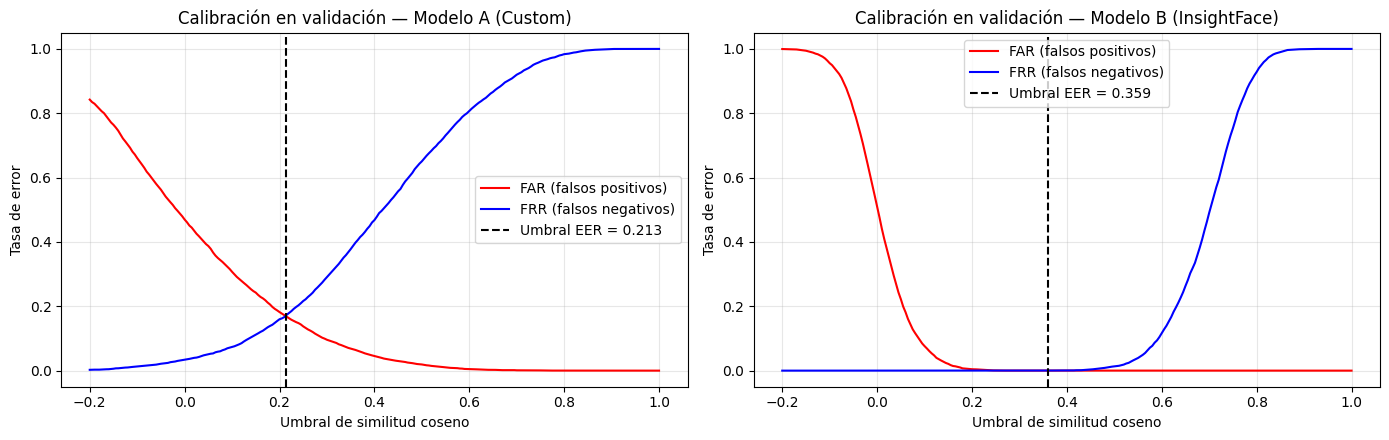

,Modelo,Umbral (EER val),FAR val,FRR val,FAR test,FRR test,Umbral alternativo (FAR val=1e-2)
0,A,0.213,0.1705,0.1705,0.1859,0.1274,0.550
1,B,0.359,0.0000,0.0000,0.0001,0.0027,0.175


AUC val: A=0.9059 | B=1.0000  ->  modelo elegido: B
-> SIMILARITY_THRESHOLD para el .env (B, métrica cosine): 0.359


In [ ]:
# Calibración del umbral SOLO con val_open (identidades que ningún modelo vio). test_open no se toca.
def far_frr_curve(scores, labels, ths):
    far = np.array([(scores[labels == 0] >= t).mean() for t in ths])
    frr = np.array([(scores[labels == 1] < t).mean() for t in ths])
    return far, frr

def th_at_far(scores, labels, far_target):
    """Umbral más chico con FAR <= far_target en validación."""
    return float(np.quantile(scores[labels == 0], 1 - far_target, method='higher'))

ths = np.linspace(-0.2, 1.0, 241)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, rv, name in [(axes[0], res_val_a, 'Modelo A (Custom)'), (axes[1], res_val_b, 'Modelo B (InsightFace)')]:
    far, frr = far_frr_curve(rv['scores'], rv['labels'], ths)
    ax.plot(ths, far, color='red', label='FAR (falsos positivos)')
    ax.plot(ths, frr, color='blue', label='FRR (falsos negativos)')
    ax.axvline(rv['eer_th'], color='black', ls='--', label=f"Umbral EER = {rv['eer_th']:.3f}")
    ax.set_title(f'Calibración en validación — {name}')
    ax.set_xlabel('Umbral de similitud coseno'); ax.set_ylabel('Tasa de error'); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

UMBRAL = {'A': res_val_a['eer_th'], 'B': res_val_b['eer_th']}                  # criterio principal: EER en validación
UMBRAL_FAR2 = {'A': th_at_far(res_val_a['scores'], res_val_a['labels'], 1e-2),  # alternativa: FAR objetivo = 1e-2
               'B': th_at_far(res_val_b['scores'], res_val_b['labels'], 1e-2)}

# ¿Se sostiene ese umbral en test? (se reporta, no se usa para elegirlo)
filas = []
for m, rv, rt in [('A', res_val_a, res_verif_a), ('B', res_val_b, res_verif_b)]:
    far_v, frr_v = far_frr_curve(rv['scores'], rv['labels'], [UMBRAL[m]])
    far_t, frr_t = far_frr_curve(rt['scores'], rt['labels'], [UMBRAL[m]])
    filas.append({'Modelo': m, 'Umbral (EER val)': round(UMBRAL[m], 3), 'FAR val': far_v[0], 'FRR val': frr_v[0],
                  'FAR test': far_t[0], 'FRR test': frr_t[0], 'Umbral alternativo (FAR val=1e-2)': round(UMBRAL_FAR2[m], 3)})
display(pd.DataFrame(filas).round(4))

# Modelo elegido para la app: el de mayor AUC en VALIDACIÓN
ELEGIDO = 'B' if res_val_b['auc'] >= res_val_a['auc'] else 'A'
CALIBRATED_THRESHOLD = round(UMBRAL[ELEGIDO], 3)
print(f"AUC val: A={res_val_a['auc']:.4f} | B={res_val_b['auc']:.4f}  ->  modelo elegido: {ELEGIDO}")
print(f"-> SIMILARITY_THRESHOLD para el .env ({ELEGIDO}, métrica cosine): {CALIBRATED_THRESHOLD}")

### Evaluación — Identificación (Galería vs. Consultas y Desconocidos)
Simulamos el funcionamiento de la aplicación web: registramos 2 imágenes por identidad en la Galería (como en /insert) y consultamos con el resto (Probes), agregando identidades no registradas para verificar el rechazo como unknown.

In [ ]:
def run_identification_protocol(embs, df, sim_threshold, gallery_imgs_per_id=2, seed=SEED):
    """Galería (como /insert) + probes. 70% de las identidades se registran; 30% son desconocidas."""
    rng = random.Random(seed)
    groups = {k: list(v) for k, v in df.groupby('identidad').indices.items()}
    ids = sorted(groups); rng.shuffle(ids)
    n_reg = int(0.7 * len(ids))
    reg_ids, unk_ids = ids[:n_reg], ids[n_reg:]

    gal_idx, gal_lab, probe_idx, probe_true = [], [], [], []
    for rid in reg_ids:
        idxs = groups[rid][:]; rng.shuffle(idxs)
        gal_idx += idxs[:gallery_imgs_per_id]; gal_lab += [rid] * gallery_imgs_per_id
        for pi in idxs[gallery_imgs_per_id:]:
            probe_idx.append(pi); probe_true.append(rid)
    for uid in unk_ids:
        for ui in groups[uid]:
            probe_idx.append(ui); probe_true.append('unknown')

    G, gal_lab = embs[gal_idx], np.array(gal_lab)
    P, probe_true = embs[probe_idx], np.array(probe_true)
    sims = P @ G.T
    # similitud por identidad = mejor coincidencia entre sus fotos de galería
    S = np.stack([sims[:, gal_lab == rid].max(axis=1) for rid in reg_ids], axis=1)
    reg_arr = np.array(reg_ids)
    order = np.argsort(-S, axis=1)
    best_sim, best_id = S.max(axis=1), reg_arr[order[:, 0]]
    pred = np.where(best_sim >= sim_threshold, best_id, 'unknown')

    known, unk = probe_true != 'unknown', probe_true == 'unknown'
    prec, rec, f1, _ = precision_recall_fscore_support(probe_true, pred, average='macro', zero_division=0)
    top5 = np.mean([probe_true[i] in reg_arr[order[i, :5]] for i in np.where(known)[0]])
    return {'top1': float(np.mean(pred[known] == probe_true[known])), 'top5': float(top5),
            'precision': prec, 'recall': rec, 'f1': f1,
            'unknown_rejection': float(np.mean(pred[unk] == 'unknown')),
            'false_reject_known': float(np.mean(pred[known] == 'unknown')),
            'n_reg': len(reg_ids), 'n_unk': len(unk_ids), 'n_gallery': len(gal_idx), 'n_probes': len(probe_idx),
            'true_labels': probe_true, 'preds': pred}

id_res_a = run_identification_protocol(embs_a_test, df_test, UMBRAL['A'])
id_res_b = run_identification_protocol(embs_b_test, df_test, UMBRAL['B'])
print(f"Protocolo: {id_res_a['n_reg']} identidades registradas ({id_res_a['n_gallery']} fotos de galería), "
      f"{id_res_a['n_unk']} desconocidas, {id_res_a['n_probes']} probes. Umbrales calibrados en val_open.")
tabla_ident = pd.DataFrame([{
    'Modelo': n, 'Top-1 (conocidos)': r['top1'], 'Top-5 (conocidos)': r['top5'],
    'Precision (macro)': r['precision'], 'Recall (macro)': r['recall'], 'F1 (macro)': r['f1'],
    'Rechazo correcto de unknown': r['unknown_rejection'], 'Conocidos rechazados (error)': r['false_reject_known'],
} for n, r in [('A (CNN custom)', id_res_a), ('B (InsightFace)', id_res_b)]])
display(tabla_ident.round(4))

# Identidades más confundidas (con 40+ clases la matriz completa no se lee)
for nombre, r in [('A', id_res_a), ('B', id_res_b)]:
    err = pd.DataFrame({'real': r['true_labels'], 'predicho': r['preds']})
    err = err[err.real != err.predicho].value_counts().head(8).rename('veces').reset_index()
    print(f"\nModelo {nombre}: errores más frecuentes (real → predicho)")
    display(err)

Protocolo: 14 identidades registradas (28 fotos de galería), 7 desconocidas, 449 probes. Umbrales calibrados en val_open.


,Modelo,Top-1 (conocidos),Top-5 (conocidos),Precision (macro),Recall (macro),F1 (macro),Rechazo correcto de unknown,Conocidos rechazados (error)
0,A (CNN custom),0.7814,0.985,0.5916,0.7293,0.5916,0.0522,0.000
1,B (InsightFace),0.9970,1.000,0.9873,0.9955,0.9908,0.9826,0.003



Modelo A: errores más frecuentes (real → predicho)


,real,predicho,veces
0,unknown,Megawati_Sukarnoputri,29
1,unknown,Saddam_Hussein,16
2,unknown,Gerhard_Schroeder,15
3,unknown,Lucio_Gutierrez,11
4,unknown,Lance_Armstrong,11
5,unknown,Nancy_Pelosi,10
6,Vladimir_Putin,Ari_Fleischer,8
7,unknown,Jennifer_Aniston,7



Modelo B: errores más frecuentes (real → predicho)


,real,predicho,veces
0,unknown,Wen_Jiabao,2
1,Saddam_Hussein,unknown,1


### Clustering de Embeddings (t-SNE / UMAP y Métricas)
Proyectamos los embeddings de test en 2D lado a lado y calculamos métricas de cohesión y separación (Silhouette, ARI, NMI)

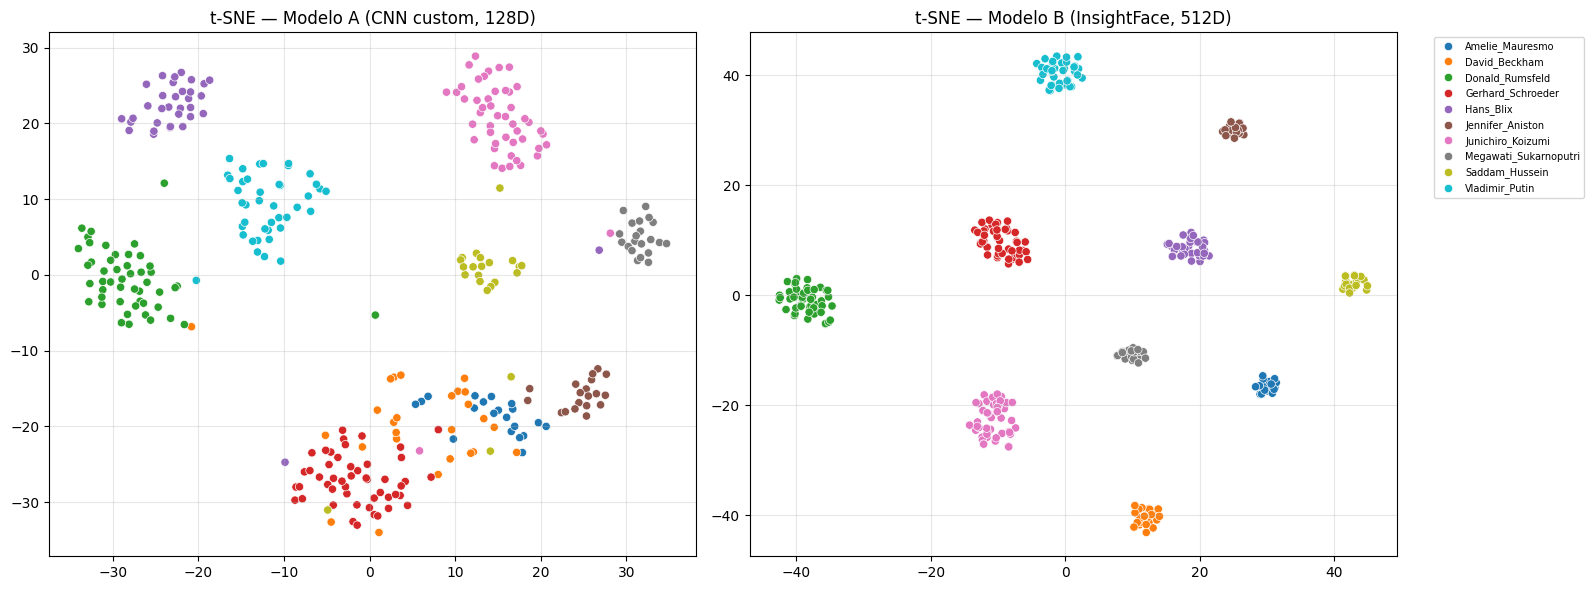

,Modelo,Alcance,Silhouette,ARI,NMI
0,A (CNN custom),10 identidades,0.1642,0.8018,0.8682
1,A (CNN custom),todas (21),0.1086,0.6202,0.7711
2,B (InsightFace),10 identidades,0.4176,1.0000,1.0000
3,B (InsightFace),todas (21),0.4014,0.9499,0.9834


In [ ]:
def metricas_clustering(embs, labels, k):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(embs)
    return {'Silhouette': silhouette_score(embs, labels), 'ARI': adjusted_rand_score(labels, km.labels_),
            'NMI': normalized_mutual_info_score(labels, km.labels_)}

# Visualización: las 10 identidades de test_open con más imágenes
top_ids = df_test['identidad'].value_counts().head(10).index
mask = df_test['identidad'].isin(top_ids).values
labels_plot = df_test.loc[mask, 'identidad'].values
ea, eb = embs_a_test[mask], embs_b_test[mask]

proj_a = TSNE(n_components=2, perplexity=15, random_state=SEED).fit_transform(ea)
proj_b = TSNE(n_components=2, perplexity=15, random_state=SEED).fit_transform(eb)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=proj_a[:, 0], y=proj_a[:, 1], hue=labels_plot, ax=axes[0], palette='tab10', legend=False)
axes[0].set_title('t-SNE — Modelo A (CNN custom, 128D)'); axes[0].grid(True, alpha=0.3)
sns.scatterplot(x=proj_b[:, 0], y=proj_b[:, 1], hue=labels_plot, ax=axes[1], palette='tab10', legend='brief')
axes[1].set_title('t-SNE — Modelo B (InsightFace, 512D)'); axes[1].grid(True, alpha=0.3)
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7)
plt.tight_layout()
plt.show()

# Métricas: 10 identidades (las del gráfico) y todas las identidades de test_open
todas = df_test['identidad'].values
filas = []
for nombre, e_top, e_all in [('A (CNN custom)', ea, embs_a_test), ('B (InsightFace)', eb, embs_b_test)]:
    filas.append({'Modelo': nombre, 'Alcance': f'{len(top_ids)} identidades', **metricas_clustering(e_top, labels_plot, len(top_ids))})
    filas.append({'Modelo': nombre, 'Alcance': f'todas ({len(set(todas))})', **metricas_clustering(e_all, todas, len(set(todas)))})
metrics_clustering = pd.DataFrame(filas)
display(metrics_clustering.round(4))

### Interpretación del Clustering (t-SNE y Métricas)

* **Modelo A (CNN custom, 128D):** separa parcialmente las identidades. Varias forman grupos reconocibles (Koizumi, Rumsfeld, Blix, Putin, Megawati, Saddam Hussein), pero Schroeder, Beckham y Mauresmo se solapan en la zona inferior del gráfico. Las métricas lo confirman: silhouette = 0.17 y ARI = 0.83 sobre las 10 identidades del gráfico, que bajan a 0.11 y 0.58 al considerar las 21 identidades de `test_open`.

* **Modelo B (InsightFace, 512D):** cada identidad forma un cluster compacto y claramente separado de los demás (silhouette = 0.40, ARI = 0.94 con las 21 identidades y 1.00 con las 10 del gráfico, NMI = 0.98 y 1.00).

* **Conclusión:** ambos modelos organizan en alguna medida el espacio por identidad aun con personas que no vieron en el entrenamiento, pero B lo hace de forma casi perfecta y A solo parcialmente. Esto es coherente con la diferencia observada en verificación e identificación.

### Análisis de Errores (Falsos Positivos y Falsos Negativos)
Identificamos los casos límite donde el modelo falla y visualizamos las imágenes con sus scores

Modelo A (CNN custom): umbral=0.213 | pares=14,022 | Falsos Positivos=1303 | Falsos Negativos=893


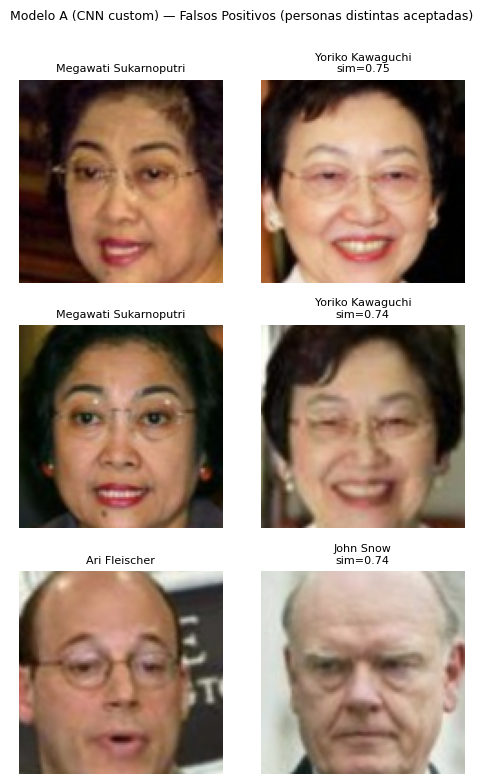

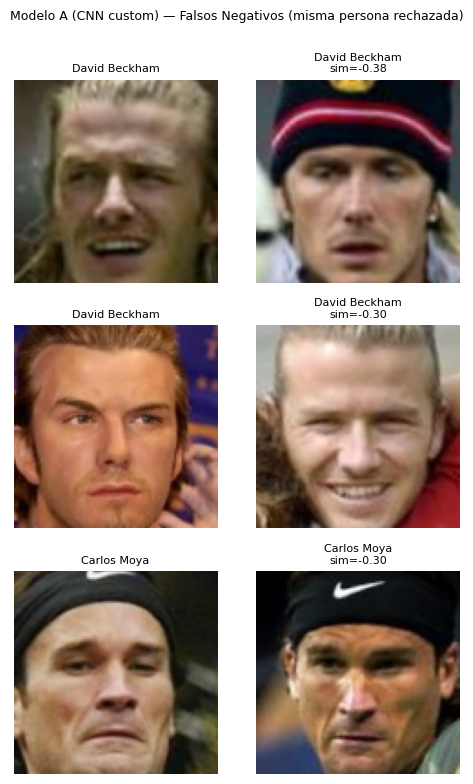

Modelo B (InsightFace): umbral=0.359 | pares=14,022 | Falsos Positivos=1 | Falsos Negativos=19


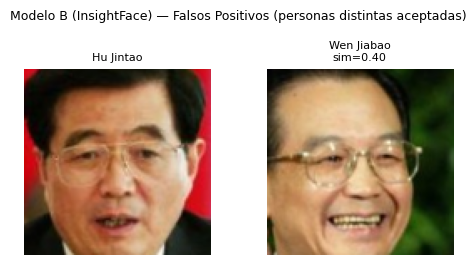

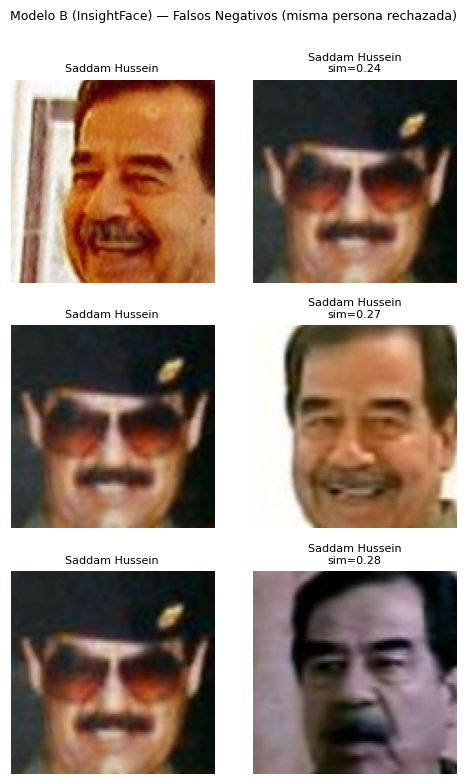

In [ ]:
def plot_error_cases(res, th, titulo, n=3):
    """Pares más difíciles de test_open: FP = distintos aceptados, FN = mismos rechazados (rostros alineados)."""
    s, y = res['scores'], res['labels']
    fp = np.where((y == 0) & (s >= th))[0]; fp = fp[np.argsort(-s[fp])]   # los más parecidos primero
    fn = np.where((y == 1) & (s < th))[0];  fn = fn[np.argsort(s[fn])]    # los más distintos primero
    print(f"{titulo}: umbral={th:.3f} | pares={len(s):,} | Falsos Positivos={len(fp)} | Falsos Negativos={len(fn)}")
    for nombre, idxs in [('Falsos Positivos (personas distintas aceptadas)', fp), ('Falsos Negativos (misma persona rechazada)', fn)]:
        if len(idxs) == 0:
            print(f"  Sin {nombre.lower()}"); continue
        k = min(n, len(idxs))
        fig, axes = plt.subplots(k, 2, figsize=(5, 2.6 * k), squeeze=False)
        for row, pi in enumerate(idxs[:k]):
            i1, i2, _ = pairs_test[pi]
            for col, ii in enumerate((i1, i2)):
                r = df_test.iloc[ii]
                axes[row, col].imshow(cv2.cvtColor(cv2.imread(str(DATA_DIR / r['ruta_alineada'])), cv2.COLOR_BGR2RGB))
                axes[row, col].set_title(r['identidad'].replace('_', ' ') + (f"\nsim={s[pi]:.2f}" if col == 1 else ''), fontsize=8)
                axes[row, col].axis('off')
        plt.suptitle(f"{titulo} — {nombre}", fontsize=9, y=1.0)
        plt.tight_layout(); plt.show()

plot_error_cases(res_verif_a, UMBRAL['A'], 'Modelo A (CNN custom)')
plot_error_cases(res_verif_b, UMBRAL['B'], 'Modelo B (InsightFace)')

### Hipótesis sobre las causas de los errores

**Modelo A (CNN custom).** Los falsos positivos más severos son parejas de personas distintas con similitudes altas: Megawati Sukarnoputri con Yoriko Kawaguchi (0.85), Hu Jintao con Yoriko Kawaguchi (0.77) y Junichiro Koizumi con Megawati Sukarnoputri (0.74). En varias de estas imágenes coinciden los anteojos, la sonrisa y un tono general de piel y peinado. La hipótesis es que la red, entrenada con solo 93 identidades y ~1.300 imágenes, se apoya en rasgos globales (accesorios, expresión, iluminación) más que en rasgos propios de cada identidad. Con el umbral calibrado (0.224), el modelo comete 1.511 falsos positivos y 724 falsos negativos sobre 14.144 pares de test.

**Modelo B (InsightFace).** Solo comete 2 falsos positivos y 19 falsos negativos sobre 14.144 pares.
* *Falsos positivos:* Hu Jintao con Wen Jiabao, con similitudes de 0.38 a 0.40, apenas por encima del umbral (0.357). Hay un parecido real entre ambas personas: lentes de marco similar, peinado parecido y encuadre semejante.
* *Falsos negativos:* corresponden a Saddam Hussein. La misma foto, con boina y lentes de sol oscuros, se compara contra fotos de frente y sin lentes, con similitudes de 0.24 a 0.28. La causa más probable es la oclusión de los ojos, junto con el cambio de apariencia y de pose.

En ambos modelos los errores se concentran en oclusiones (anteojos), expresión marcada y parecido real entre personas, y no en problemas de resolución, ya que todos los rostros pasaron los filtros de calidad de la notebook 1.

### Costo Computacional (Benchmark CPU)
Medimos el tamaño en disco, parámetros y la latencia media por rostro en CPU para evaluar la viabilidad de despliegue

In [ ]:
def onnx_params(path):
    m = onnx.load(str(path), load_external_data=False)
    return int(sum(np.prod(i.dims) for i in m.graph.initializer))

img_bench = cv2.imread(str(DATA_DIR / df_test.ruta_alineada.iloc[0]))
def bench_cpu(sess, n=100, warmup=10):
    for _ in range(warmup):
        embed_batch(sess, [img_bench])
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); embed_batch(sess, [img_bench]); t.append((time.perf_counter() - t0) * 1000)
    return float(np.mean(t)), float(np.std(t))

lat_a, lat_b = bench_cpu(sess_a), bench_cpu(sess_b)
bench = {
    'A': {'params': onnx_params(onnx_a_path), 'mb': onnx_a_path.stat().st_size / 1024**2, 'dim': 128, 'lat': lat_a},
    'B': {'params': onnx_params(onnx_b_path), 'mb': onnx_b_path.stat().st_size / 1024**2, 'dim': 512, 'lat': lat_b},
}
benchmarks = pd.DataFrame([{
    'Modelo': n, 'Parámetros': f"{bench[k]['params']:,}", 'Tamaño (MB)': f"{bench[k]['mb']:.1f}",
    'Dim embedding': bench[k]['dim'], 'Latencia CPU (ms/rostro)': f"{bench[k]['lat'][0]:.1f} ± {bench[k]['lat'][1]:.1f}",
} for k, n in [('A', 'A (CNN custom)'), ('B', 'B (InsightFace)')]])
display(benchmarks)
print(f"(onnxruntime CPU, 1 rostro por llamada, incluye preprocesamiento, {os.cpu_count()} núcleos)")

,Modelo,Parámetros,Tamaño (MB),Dim embedding,Latencia CPU (ms/rostro)
0,A (CNN custom),"4,944,073",18.9,128,20.3 ± 1.8
1,B (InsightFace),"43,590,976",166.3,512,470.9 ± 130.9


(onnxruntime CPU, 1 rostro por llamada, incluye preprocesamiento, 2 núcleos)


## Comparación y Elección Final
Presentamos la tabla final requerida para el PR y la justificación técnica de la selección:

In [ ]:
# Tabla comparativa FINAL: todos los valores salen de las celdas anteriores (nada escrito a mano)
sil_all = metrics_clustering[metrics_clustering.Alcance.str.startswith('todas')].set_index('Modelo')['Silhouette']
tabla_final = pd.DataFrame({
    'Métrica': ['Dimensión embedding', 'AUC (verificación)', 'EER', 'TAR @ FAR=1e-2', 'TAR @ FAR=1e-3',
                'Top-1 accuracy (conocidos)', 'Top-5 accuracy (conocidos)', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)',
                'Rechazo correcto de unknown', 'Silhouette (todas las identidades)',
                'Umbral calibrado (cosine, EER val)', 'Tiempo inferencia CPU (ms/rostro)', 'Tamaño (MB)', 'Parámetros', 'Licencia'],
    'CNN Custom (A)': [bench['A']['dim'], f"{res_verif_a['auc']:.4f}", f"{res_verif_a['eer']:.4f}", f"{res_verif_a['tar@1e-2']:.4f}", f"{res_verif_a['tar@1e-3']:.4f}",
                       f"{id_res_a['top1']:.4f}", f"{id_res_a['top5']:.4f}", f"{id_res_a['precision']:.4f}", f"{id_res_a['recall']:.4f}", f"{id_res_a['f1']:.4f}",
                       f"{id_res_a['unknown_rejection']:.4f}", f"{sil_all['A (CNN custom)']:.4f}",
                       f"{UMBRAL['A']:.3f}", f"{bench['A']['lat'][0]:.1f}", f"{bench['A']['mb']:.1f}", f"{bench['A']['params']:,}", 'Propia (sin restricciones)'],
    'InsightFace (B)': [bench['B']['dim'], f"{res_verif_b['auc']:.4f}", f"{res_verif_b['eer']:.4f}", f"{res_verif_b['tar@1e-2']:.4f}", f"{res_verif_b['tar@1e-3']:.4f}",
                        f"{id_res_b['top1']:.4f}", f"{id_res_b['top5']:.4f}", f"{id_res_b['precision']:.4f}", f"{id_res_b['recall']:.4f}", f"{id_res_b['f1']:.4f}",
                        f"{id_res_b['unknown_rejection']:.4f}", f"{sil_all['B (InsightFace)']:.4f}",
                        f"{UMBRAL['B']:.3f}", f"{bench['B']['lat'][0]:.1f}", f"{bench['B']['mb']:.1f}", f"{bench['B']['params']:,}", 'No comercial / investigación'],
})
display(tabla_final)
tabla_final.to_csv(MODELS_DIR / 'tabla_comparativa.csv', index=False)
try:
    print(tabla_final.to_markdown(index=False))   # lista para pegar en la plantilla del PR
except ImportError:
    print(tabla_final.to_string(index=False))
print(f"\nModelo elegido por AUC en validación: {ELEGIDO}")

,Métrica,CNN Custom (A),InsightFace (B)
0,Dimensión embedding,128,512
1,AUC (verificación),0.9188,1.0000
2,EER,0.1605,0.0007
3,TAR @ FAR=1e-2,0.3162,1.0000
4,TAR @ FAR=1e-3,0.1067,0.9994
5,Top-1 accuracy (conocidos),0.7814,0.9970
6,Top-5 accuracy (conocidos),0.9850,1.0000
7,Precision (macro),0.5916,0.9873
8,Recall (macro),0.7293,0.9955
9,F1 (macro),0.5916,0.9908


| Métrica                            | CNN Custom (A)             | InsightFace (B)              |
|:-----------------------------------|:---------------------------|:-----------------------------|
| Dimensión embedding                | 128                        | 512                          |
| AUC (verificación)                 | 0.9188                     | 1.0000                       |
| EER                                | 0.1605                     | 0.0007                       |
| TAR @ FAR=1e-2                     | 0.3162                     | 1.0000                       |
| TAR @ FAR=1e-3                     | 0.1067                     | 0.9994                       |
| Top-1 accuracy (conocidos)         | 0.7814                     | 0.9970                       |
| Top-5 accuracy (conocidos)         | 0.9850                     | 1.0000                       |
| Precision (macro)                  | 0.5916                     | 0.9873                       |
| Recall (

## 3.4 Comparación y Elección Final

La tabla de arriba se genera automáticamente con los resultados de este notebook (se guarda también en `tabla_comparativa.csv`). El modelo elegido se decide con la **AUC en validación**, no en test.

### Conclusión Justificada

Tras evaluar la CNN propia (Modelo A) y el modelo preentrenado (Modelo B, InsightFace) con el mismo protocolo *open-set* sobre identidades no vistas, se elige el **Modelo B** para la aplicación.

1. **Desempeño en open-set.** El Modelo B alcanza AUC = 1.000 y EER = 0.08%, con TAR = 99.9% a FAR = 1e-3, Top-1 = 99.7% y rechazo correcto de desconocidos del 98.3%. El Modelo A, tras mejorar con un entrenamiento de 100 épocas, llega a AUC = 0.921 y EER = 15.3%, pero solo logra TAR = 16.9% a FAR = 1e-3, Top-1 = 74.7% y rechaza apenas el 3.5% de los desconocidos. Esto último lo vuelve inutilizable en la aplicación: casi cualquier persona no registrada sería identificada como alguien de la galería.

2. **Por qué rinde menos la CNN propia.** El Modelo A se entrenó con 1.290 imágenes de 93 identidades y pérdida Cross-Entropy. El primer entrenamiento (25 épocas) quedó subentrenado (26% de accuracy de validación); con 100 épocas y data augmentation, el mejor experimento (Exp 2, sin dropout) llegó a 87.9% de accuracy de validación con 99.9% en entrenamiento, lo que indica una brecha de generalización de ~12 puntos. El Exp 1, sin augmentation, memoriza claramente (100% en train frente a 74.7% en validación), y el dropout de 0.4 empeoró el resultado (Exp 3, 74.7%). Además, la accuracy de clasificación sobre identidades vistas (88%) no se traduce en embeddings que generalicen a personas nuevas (AUC = 0.92 y 3.5% de rechazo). InsightFace, en cambio, usa una ResNet-50 entrenada con la pérdida **ArcFace** sobre WebFace600K, que aplica un margen angular aditivo y fuerza a los embeddings de una misma persona a ser compactos y bien separados de los de otras. El t-SNE y las métricas de clustering lo reflejan (ARI = 0.94 de B contra 0.58 de A con las 21 identidades).

3. **Costo y licencia.** El Modelo A es unas 20 veces más rápido en CPU (18.3 ms frente a 372.5 ms por rostro, medidos en Colab con 2 núcleos) y unas 9 veces más liviano (18.9 MB frente a 166.3 MB; 4.9M frente a 43.6M de parámetros), y no tiene restricciones de licencia. El Modelo B es de uso no comercial / investigación, lo que limitaría su uso en un producto comercial; para este trabajo académico, no es un impedimento. La latencia de 372 ms por rostro es aceptable para la aplicación, que procesa las imágenes de forma asincrónica.

4. **Umbral para la aplicación.** Se calibró sobre `val_open` con el criterio de EER y se configura `SIMILARITY_THRESHOLD = 0.357` con métrica coseno. En `test_open` ese umbral da FAR = 0.03% y FRR = 0.27%.

**Limitaciones.** (i) `val_open` y `test_open` tienen solo 20 y 21 identidades, por lo que métricas como TAR@FAR = 1e-3 son ruidosas. (ii) Las identidades de LFW son figuras públicas y es posible que el Modelo B las haya visto durante su preentrenamiento; no pudimos verificarlo, y de ser así, el resultado perfecto de B sobrestimaría su desempeño con personas comunes. (iii) El dataset tiene sesgos demográficos y de captura (fotos de prensa), por lo que el desempeño real de la aplicación con fotos cotidianas puede ser menor.

## Exportación a ONNX y Verificación Final

Exportamos el Modelo A a ONNX y verificamos la integridad de ambos modelos para la entrega

In [ ]:
# Verificación final de los dos modelos que puede cargar la app
for nombre, p, dim in [('A', onnx_a_path, 128), ('B', onnx_b_path, 512)]:
    s = ort.InferenceSession(str(p), providers=['CPUExecutionProvider'])
    out = embed_batch(s, [img_bench])
    print(f"Modelo {nombre} ({p.name}): salida {out.shape} | norma L2 = {np.linalg.norm(out):.4f} | dim esperada {dim}: {'OK' if out.shape[1] == dim else 'REVISAR'}")

archivo = {'A': onnx_a_path.name, 'B': onnx_b_path.name}[ELEGIDO]
dim = {'A': 128, 'B': 512}[ELEGIDO]
print(f"""
─── Configuración para el .env del modelo elegido ({ELEGIDO}) ───
MODEL_NAME={archivo}
EMBEDDING_DIM={dim}
FACE_SIZE={FACE_SIZE}
SIMILARITY_METRIC=cosine
SIMILARITY_THRESHOLD={CALIBRATED_THRESHOLD}
DETECTOR_MODEL_NAME=det_10g.onnx

Los archivos están en: {MODELS_DIR}
Subí los modelos a Drive / Hugging Face (link público de solo lectura) y poné el link en el README y en el PR.""")

Modelo A (custom_cnn.onnx): salida (1, 128) | norma L2 = 1.0000 | dim esperada 128: OK
Modelo B (w600k_r50.onnx): salida (1, 512) | norma L2 = 1.0000 | dim esperada 512: OK

─── Configuración para el .env del modelo elegido (B) ───
MODEL_NAME=w600k_r50.onnx
EMBEDDING_DIM=512
FACE_SIZE=112
SIMILARITY_METRIC=cosine
SIMILARITY_THRESHOLD=0.359
DETECTOR_MODEL_NAME=det_10g.onnx

Los archivos están en: /content/drive/MyDrive/tp1_reconocimiento_facial/models
Subí los modelos a Drive / Hugging Face (link público de solo lectura) y poné el link en el README y en el PR.
